## Objectives

In this self-study lab you will

- store a data set with several features in a design matrix $\mathbf X$ and use the notation $x_j^{(i)}$;
- compute predictions with a loop, with `np.dot` for one example, and for all examples at once with `X @ w + b`;
- measure how much faster vectorised code is;
- implement the cost function and its gradient for $n$ features, from two nested loops to a fully vectorised version, and check the gradient with finite differences;
- run gradient descent and compare the result with scikit-learn.

## Tools

- **NumPy** and **Matplotlib**, as in Labs 1 and 2;
- **scikit-learn**, to load the data and as a reference solution;
- the standard modules **time** and **timeit**, to measure running times.

In [1]:
import time
import timeit
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression

## Problem statement

As in the lecture, we use the diabetes data set, now with **four** features per patient: age, sex, body mass index (BMI) and average blood pressure (BP). The target $y$ is again the disease progression after one year. The feature `sex` is coded as `1` or `2`.

In [2]:
diabetes = load_diabetes(scaled=False)
X_train = diabetes.data[:, :4]             # the first four columns: age, sex, bmi, bp
y_train = diabetes.target
feature_names = diabetes.feature_names[:4]
print(feature_names)
print(X_train[:4])
print(y_train[:4])

['age', 'sex', 'bmi', 'bp']
[[ 59.    2.   32.1 101. ]
 [ 48.    1.   21.6  87. ]
 [ 72.    2.   30.5  93. ]
 [ 24.    1.   25.3  84. ]]
[151.  75. 141. 206.]


These are the first rows of the table in the lecture.

### The design matrix and its notation

The examples are stored as the **rows** of the **design matrix** $\mathbf X$, and the features as its **columns**. With $m$ examples and $n$ features, $\mathbf X$ has shape $(m, n)$:
$$
\mathbf X = \begin{pmatrix}
x_1^{(1)} & x_2^{(1)} & \cdots & x_n^{(1)}\\
\vdots & \vdots & & \vdots\\
x_1^{(m)} & x_2^{(m)} & \cdots & x_n^{(m)}
\end{pmatrix},
\qquad
\mathbf y = \begin{pmatrix} y^{(1)}\\ \vdots\\ y^{(m)}\end{pmatrix}.
$$

- $\mathbf x^{(i)} = \big(x_1^{(i)}, \dots, x_n^{(i)}\big)$ contains all features of example $i$ (row $i$);
- $x_j^{(i)}$ is the value of feature $j$ in example $i$: superscript = row (example), subscript = column (feature).

Since Python counts from $0$, $x_j^{(i)}$ is `X_train[i-1, j-1]`, the row $\mathbf x^{(i)}$ is `X_train[i-1]` and the column of feature $j$ is `X_train[:, j-1]`.

In [3]:
m, n = X_train.shape
print(f"m = {m} examples, n = {n} features")
print(f"x^(2)   = {X_train[1]}")      # all features of patient 2
print(f"x_3^(2) = {X_train[1, 2]}")   # BMI of patient 2

m = 442 examples, n = 4 features
x^(2)   = [48.   1.  21.6 87. ]
x_3^(2) = 21.6


**Your turn** (from the lecture): use Python to find $x_4^{(3)}$, $x_3^{(1)}$ and $x_2^{(4)}$.

::: {.callout-tip collapse="true" title="Solution"}

In [4]:
print(X_train[2, 3], X_train[0, 2], X_train[3, 1])   # 93, 32.1, 1

93.0 32.1 1.0


:::

## Model prediction with multiple features

The model with $n$ features is
$$
f_{\mathbf w,b}(\mathbf x) = w_1x_1 + w_2x_2 + \dots + w_nx_n + b = \sum_{j=1}^{n} w_jx_j + b = \mathbf w\cdot\mathbf x + b ,
$$
with one weight $w_j$ per feature, collected in the vector $\mathbf w = (w_1, \dots, w_n)$, and a single bias $b$. In NumPy, $\mathbf w$ is a 1D array of length $n$, and $w_1$ is `w[0]`.

To try out the prediction, we use parameters that are close to the best ones (we compute those at the end of this lab).

In [5]:
w = np.array([0.1, -10.0, 8.5, 1.4])
b = -200.0

### One example, with a loop

The first version follows the sum $\sum_j w_jx_j + b$ term by term.

In [6]:
def predict_loop(x, w, b):
    """Prediction w . x + b for ONE example x (1D array of n features), with a loop."""
    f = 0.0
    for j in range(len(w)):
        f = f + w[j] * x[j]
    return f + b

print(f"prediction for patient 1: {predict_loop(X_train[0], w, b):.2f}, target: {y_train[0]}")

prediction for patient 1: 200.15, target: 151.0


### One example, vectorised

The sum $\sum_j w_jx_j$ is the **dot product** $\mathbf w\cdot\mathbf x$, which NumPy computes with `np.dot(x, w)` or, equivalently, `x @ w`.

In [7]:
def predict(x, w, b):
    """Vectorised prediction w . x + b."""
    return np.dot(x, w) + b

print(f"prediction for patient 1: {predict(X_train[0], w, b):.2f}")

prediction for patient 1: 200.15


### All examples at once

The same function works if we pass the whole matrix `X_train` instead of a single row. For a 2D array `X` and a 1D array `w`, `np.dot(X, w)` (or `X @ w`) computes the dot product of **every row** of $\mathbf X$ with $\mathbf w$:
$$
\mathbf X\mathbf w = \begin{pmatrix}
\mathbf x^{(1)}\cdot\mathbf w\\ \vdots\\ \mathbf x^{(m)}\cdot\mathbf w
\end{pmatrix},
\qquad
\hat{\mathbf y} = \mathbf X\mathbf w + b ,
$$
where $b$ is added to every entry. So all $m$ predictions take one line of code.

In [8]:
y_hat = predict(X_train, w, b)     # shape (m,)
print(f"y_hat.shape = {y_hat.shape}")
print(f"first predictions: {y_hat[:4].round(2)}")
print(f"first targets:     {y_train[:4]}")

y_hat.shape = (442,)
first predictions: [200.15 100.2  176.65 125.05]
first targets:     [151.  75. 141. 206.]


::: {.callout-warning title="Keep vectors one-dimensional"}
If `w` is stored as a column, with shape `(n, 1)` instead of `(n,)`, then `X @ w` has shape `(m, 1)`. Subtracting `y` of shape `(m,)` then silently produces an `(m, m)` matrix through NumPy broadcasting, and every result computed from it is wrong. Check shapes when results look strange:

In [9]:
w_column = w.reshape(-1, 1)                     # shape (4, 1)
print((X_train @ w - y_train).shape)            # (442,)     correct
print((X_train @ w_column - y_train).shape)     # (442, 442) wrong!

(442,)
(442, 442)


:::

### How much faster is vectorised code?

The lecture compared an explicit loop with `np.dot` for two vectors with one million entries. Run the cell a few times: the exact numbers depend on your computer.

In [10]:
rng = np.random.default_rng(0)
a = rng.random(1_000_000)
c = rng.random(1_000_000)

t0 = time.perf_counter()
s = 0.0
for i in range(len(a)):          # explicit Python loop
    s += a[i] * c[i]
t_loop = time.perf_counter() - t0

t0 = time.perf_counter()
s_vec = np.dot(a, c)             # vectorised
t_vec = time.perf_counter() - t0

print(f"loop: {1000 * t_loop:.1f} ms, vectorised: {1000 * t_vec:.2f} ms, "
      f"speed-up: {t_loop / t_vec:.0f}x, same result: {np.isclose(s, s_vec)}")

loop: 231.9 ms, vectorised: 1.19 ms, speed-up: 195x, same result: True


## The cost function

The squared-error cost has the same form as in Lab 2, with $\mathbf w\cdot\mathbf x^{(i)}$ in place of $wx^{(i)}$:
$$
J(\mathbf w,b) = \frac{1}{2m}\sum_{i=1}^{m}\big(f_{\mathbf w,b}(\mathbf x^{(i)}) - y^{(i)}\big)^2 .
$$
With the error vector $\mathbf e = \mathbf X\mathbf w + b - \mathbf y$, it is half the mean of the squared errors.

In [11]:
def compute_cost(X, y, w, b):
    """
    Squared-error cost J(w,b) for linear regression with n features.

    Args:
        X (ndarray (m,n)): data, m examples with n features
        y (ndarray (m,)) : target values
        w (ndarray (n,)) : weights
        b (scalar)       : bias
    Returns:
        cost (float)
    """
    m = X.shape[0]
    err = X @ w + b - y                 # errors of all m examples, shape (m,)
    return np.sum(err ** 2) / (2 * m)

print(f"J(w, b) = {compute_cost(X_train, y_train, w, b):.2f}")

J(w, b) = 1792.32


## The gradient of the cost

From the lecture, the partial derivatives are
$$
\frac{\partial J}{\partial w_j} = \frac{1}{m}\sum_{i=1}^{m}\big(f_{\mathbf w,b}(\mathbf x^{(i)}) - y^{(i)}\big)\,x_j^{(i)}, \quad j = 1, \dots, n,
\qquad
\frac{\partial J}{\partial b} = \frac{1}{m}\sum_{i=1}^{m}\big(f_{\mathbf w,b}(\mathbf x^{(i)}) - y^{(i)}\big):
$$
the error times the input, averaged over all examples. We implement this in three steps, removing one loop at a time.

### Version 1: two nested loops

An outer loop over the examples computes the error $e^{(i)}$ of example $i$; an inner loop over the features adds $e^{(i)}x_j^{(i)}$ to the $j$-th partial derivative.

In [12]:
def compute_gradient_two_loops(X, y, w, b):
    """Gradient of J(w,b) with loops over examples and features."""
    m, n = X.shape
    dJ_dw = np.zeros(n)
    dJ_db = 0.0
    for i in range(m):
        err = (np.dot(X[i], w) + b) - y[i]       # error of example i
        for j in range(n):
            dJ_dw[j] = dJ_dw[j] + err * X[i, j]
        dJ_db = dJ_db + err
    return dJ_dw / m, dJ_db / m

### Version 2: one loop

The index `j` appears in the same position on both sides of `dJ_dw[j] = dJ_dw[j] + err * X[i, j]`. This is the sign that the inner loop can be replaced by one vector operation: the whole loop over `j` is equivalent to `dJ_dw = dJ_dw + err * X[i]`.

In [13]:
def compute_gradient_one_loop(X, y, w, b):
    """Gradient of J(w,b) with a loop over the examples only."""
    m, n = X.shape
    dJ_dw = np.zeros(n)
    dJ_db = 0.0
    for i in range(m):
        err = (np.dot(X[i], w) + b) - y[i]
        dJ_dw = dJ_dw + err * X[i]               # all n features at once
        dJ_db = dJ_db + err
    return dJ_dw / m, dJ_db / m

### Version 3: fully vectorised

The remaining loop over the examples can also go. Entry $j$ of the matrix-vector product $\mathbf X^{\top}\mathbf e$ is $\sum_i x_j^{(i)}e^{(i)}$, exactly the sum we need, so
$$
\nabla_{\mathbf w}J = \frac{1}{m}\,\mathbf X^{\top}\mathbf e,
\qquad
\frac{\partial J}{\partial b} = \frac{1}{m}\sum_{i=1}^{m} e^{(i)},
\qquad
\mathbf e = \mathbf X\mathbf w + b - \mathbf y .
$$

In [14]:
def compute_gradient(X, y, w, b):
    """
    Vectorised gradient of the squared-error cost J(w,b).

    Returns:
        dJ_dw (ndarray (n,)): partial derivatives with respect to w_1, ..., w_n
        dJ_db (float)       : partial derivative with respect to b
    """
    m = X.shape[0]
    err = X @ w + b - y          # shape (m,)
    dJ_dw = X.T @ err / m        # shape (n,)
    dJ_db = np.sum(err) / m
    return dJ_dw, dJ_db

### Checking the gradient

As in Lab 2, we compare with central finite differences, now changing one weight $w_j$ at a time:
$$
\frac{\partial J}{\partial w_j} \approx \frac{J(\mathbf w + \varepsilon\,\mathbf e_j, b) - J(\mathbf w - \varepsilon\,\mathbf e_j, b)}{2\varepsilon},
$$
where $\mathbf e_j$ is the $j$-th unit vector (a $1$ in position $j$, zeros elsewhere).

In [15]:
def numerical_gradient(X, y, w, b, eps=1e-6):
    """Central-difference approximation of the gradient of compute_cost."""
    dJ_dw = np.zeros_like(w)
    for j in range(len(w)):
        e_j = np.zeros_like(w)
        e_j[j] = eps
        dJ_dw[j] = (compute_cost(X, y, w + e_j, b) - compute_cost(X, y, w - e_j, b)) / (2 * eps)
    dJ_db = (compute_cost(X, y, w, b + eps) - compute_cost(X, y, w, b - eps)) / (2 * eps)
    return dJ_dw, dJ_db

dJ_dw, dJ_db = numerical_gradient(X_train, y_train, w, b)
print(f"{'finite differences':27s}: dJ/dw = {dJ_dw.round(5)}, dJ/db = {dJ_db:.5f}")
for grad in [compute_gradient_two_loops, compute_gradient_one_loop, compute_gradient]:
    dJ_dw, dJ_db = grad(X_train, y_train, w, b)
    print(f"{grad.__name__:27s}: dJ/dw = {dJ_dw.round(5)}, dJ/db = {dJ_db:.5f}")

finite differences         : dJ/dw = [-263.23871   -7.78536 -139.7396  -506.39724], dJ/db = -5.26488
compute_gradient_two_loops : dJ/dw = [-263.23871   -7.78536 -139.7396  -506.39724], dJ/db = -5.26488
compute_gradient_one_loop  : dJ/dw = [-263.23871   -7.78536 -139.7396  -506.39724], dJ/db = -5.26488
compute_gradient           : dJ/dw = [-263.23871   -7.78536 -139.7396  -506.39724], dJ/db = -5.26488


All three implementations agree with the finite differences. Now compare their speed:

In [16]:
n_calls = 100
for grad in [compute_gradient_two_loops, compute_gradient_one_loop, compute_gradient]:
    t = timeit.timeit(lambda: grad(X_train, y_train, w, b), number=n_calls) / n_calls
    print(f"{grad.__name__:27s}: {1e6 * t:8.1f} microseconds per call")

compute_gradient_two_loops :    863.6 microseconds per call


compute_gradient_one_loop  :    985.1 microseconds per call
compute_gradient           :      7.5 microseconds per call


Versions 1 and 2 are similarly fast here, because the inner loop has only $n = 4$ steps. Removing the loop over the $m = 442$ examples makes the vectorised version about 100 times faster. From now on we use `compute_gradient`.

## Gradient descent with multiple features

Gradient descent updates all weights and the bias simultaneously:
$$
\mathbf w \leftarrow \mathbf w - \alpha\,\nabla_{\mathbf w}J(\mathbf w, b),
\qquad
b \leftarrow b - \alpha\,\frac{\partial J}{\partial b}(\mathbf w, b).
$$
With NumPy, `w = w - alpha * dJ_dw` updates all $n$ weights in one line. The function below is the one from the lecture; it starts from $\mathbf w = \mathbf 0$, $b = 0$ and records the cost after every iteration.

In [17]:
def gradient_descent(X, y, alpha=0.1, n_iters=1000):
    """
    Batch gradient descent for f(x) = w . x + b, starting from w = 0, b = 0.

    Args:
        X (ndarray (m,n)): design matrix
        y (ndarray (m,)) : targets
        alpha (float)    : learning rate
        n_iters (int)    : number of iterations
    Returns:
        w (ndarray (n,)), b (float): parameters after n_iters iterations
        J_history (ndarray (n_iters,)): cost at the start of every iteration
    """
    m, n = X.shape
    w = np.zeros(n)
    b = 0.0
    J_history = np.zeros(n_iters)
    for t in range(n_iters):
        err = X @ w + b - y          # (m,) errors
        dJ_dw = X.T @ err / m        # (n,) gradient
        dJ_db = np.sum(err) / m      # scalar
        w = w - alpha * dJ_dw        # simultaneous
        b = b - alpha * dJ_db        # update
        J_history[t] = np.sum(err ** 2) / (2 * m)
    return w, b, J_history

### A reference solution

To judge the result of gradient descent, we compute the exact minimiser of $J$ with scikit-learn (Lab 5 explains how it is found).

In [18]:
model = LinearRegression()
model.fit(X_train, y_train)
w_ref, b_ref = model.coef_, model.intercept_
J_min = compute_cost(X_train, y_train, w_ref, b_ref)
print(f"w_ref = {w_ref.round(3)}, b_ref = {b_ref:.2f}, J_min = {J_min:.2f}")

w_ref = [  0.135 -10.159   8.484   1.435], b_ref = -199.07, J_min = 1778.19


The weights are interpreted as in the lecture: each $w_j$ is the change in the prediction when $x_j$ increases by one unit **while all other features stay fixed**. For example, one more unit of BMI at the same age, sex and blood pressure goes with about $8.5$ points more disease progression. With BMI alone (Labs 1 and 2) the slope was $10.23$: patients with a high BMI also tend to have a high blood pressure, so part of that effect is now explained by BP.

### Running gradient descent on the raw features

The features have very different sizes: `sex` is 1 or 2, while BP is around 100. As we saw in Lab 2, large input values force a small learning rate. Here $\alpha$ must be below about $1.6\times 10^{-4}$, otherwise gradient descent diverges (try $\alpha = 2\times 10^{-4}$!). We use $\alpha = 1.5\times 10^{-4}$ and $100\,000$ iterations.

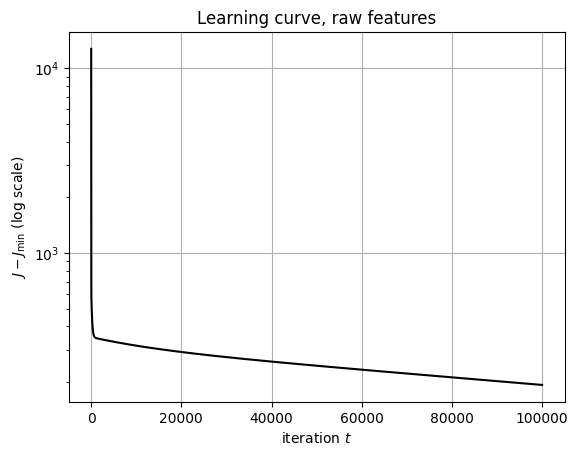

gradient descent: w = [ -0.096 -16.38    6.359   0.61 ], b = -42.21, J = 1971.15
scikit-learn:     w = [  0.135 -10.159   8.484   1.435], b = -199.07, J = 1778.19


In [19]:
w_gd, b_gd, J_hist = gradient_descent(X_train, y_train, alpha=1.5e-4, n_iters=100_000)

plt.semilogy(J_hist - J_min, 'k-')
plt.xlabel('iteration $t$')
plt.ylabel('$J - J_{\\min}$ (log scale)')
plt.title('Learning curve, raw features')
plt.grid(True)
plt.show()

print(f"gradient descent: w = {w_gd.round(3)}, b = {b_gd:.2f}, J = {J_hist[-1]:.2f}")
print(f"scikit-learn:     w = {w_ref.round(3)}, b = {b_ref:.2f}, J = {J_min:.2f}")

The cost decreases at every iteration, so the implementation works. However, after $100\,000$ iterations the cost is still about $11\%$ above its minimum, and the parameters are far from the reference values; the bias, for instance, is about $-42$ instead of $-199$. The reason is the one from Lab 2: features on very different scales turn the bowl $J$ into an extremely long and narrow valley. A small $\alpha$ is needed to stay stable across the valley, and then progress along the valley is very slow. In Lab 4 we fix this with **feature scaling**.

## Challenges

1. Change the sign in the update to `w = w + alpha * dJ_dw` and `b = b + alpha * dJ_db`, and plot the learning curve. What do you see? (This is the bug in the lecture's "learning curve looks wrong" slide.)
2. Fit the model with only BMI and BP (columns 2 and 3) using scikit-learn. Do you get the plane $\hat y = 8.52\,x_1 + 1.38\,x_2 - 203.6$ from the lecture?
3. With $m = 1000$ examples and $n = 20$ features, what are the shapes of `X`, `w`, `X @ w + b - y` and `X.T @ (X @ w + b - y)`? Check your answer with random arrays.

## Summary

- The design matrix $\mathbf X$ has one row per example and one column per feature; $x_j^{(i)}$ is `X[i-1, j-1]`.
- The model $f_{\mathbf w,b}(\mathbf x) = \mathbf w\cdot\mathbf x + b$ is `X @ w + b` for all examples at once; keep `w` and `y` one-dimensional.
- Vectorised code is shorter than loops and hundreds of times faster.
- Gradient: $\nabla_{\mathbf w}J = \frac1m\mathbf X^{\top}\mathbf e$ and $\partial J/\partial b = \frac1m\sum_i e^{(i)}$, with $\mathbf e = \mathbf X\mathbf w + b - \mathbf y$. Check gradient code with finite differences.
- On features with very different scales, gradient descent converges very slowly. **Next (Lab 4):** feature scaling and choosing the learning rate.